# LASSER, option 1: learned co-expression graph with the GEARS batching fix

**Why this study.** In upstream GEARS the co-expression GNN only reaches the first cell of each batch: it stacks
32 cells' gene embeddings but uses a single-cell `edge_index`. So the co-expression graph barely affects
predictions, and in study session 1 GEARS and LASSER came out the same. `fix_coexpress_batching=True` (opt-in;
off = upstream GEARS, bit-for-bit) gives every cell its graph messages. This study asks whether a **learned**
graph beats GEARS's Pearson graph **once the graph can act**, and checks that against two controls.

| Tier | Jobs (10 epochs each) | Question |
|---|---|---|
| 1 | `GEARS-fix` vs `LASSER-fix`, splits 1–3 | Does the learned graph help? |
| 2 | `LASSER-random-fix`, splits 1–3 | Is it the learned *partners*, or just extra edges? (same in-degrees and weights) |
| 3 | `GEARS-kNN8-fix`, splits 1–3 | Is it more than a denser Pearson graph? |
| 4 | `GEARS` (no fix), splits 1–3 | What does the fix itself change? |
| 5 | training-seed replicates (`_ts101`) of tier 1 | How large is run-to-run noise? |
| 6 | splits 4–5 for tiers 1–3 | More splits |

**Budget.** About 50 min per run on one GPU (10 epochs), so one **10-hour** session finishes tiers 1–2 and
part of tier 3 (about 10–11 runs). Jobs run in this priority order, interleaved by split, so whatever finishes
is a complete paired set. Later sessions resume where this one stopped.

**Kaggle settings:** GPU (one T4 or P100 is enough; RAM allows only one worker), **Internet on**. Run with
*Save Version → Save & Run All (Commit)*. To resume: add this notebook's previous output as input and set
`RESUME_FROM`.

Runs from option 1 use 10 epochs everywhere, so they are not compared with the 20-epoch runs of study session 1.

## A. Setup and experiments

In [1]:
# 1. Dependencies (GEARS is vendored inside lasser/).
!pip install -q torch_geometric scanpy pytest

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.8 MB/s eta 0:00:00


In [2]:
# 2. Code.
REPO_URL = "https://github.com/LegendaryDarkKnight/LASSER"
REPO_DIR = "/kaggle/working/lasser-repo"
!rm -rf {REPO_DIR} /kaggle/working/lasser
!git clone -q {REPO_URL} {REPO_DIR}
!mv {REPO_DIR}/lasser /kaggle/working/lasser
!git -C {REPO_DIR} log -1 --oneline

2de5019 (HEAD -> main, origin/main, origin/HEAD) fix code


In [3]:
# 3. Settings.
import os, shutil, time
T0 = time.time()
SESSION_HOURS = 10.0                # your limit for this session
ANALYSIS_RESERVE_HOURS = 0.6        # kept free at the end for analysis + saving outputs
EPOCHS = 10
STUDY_DIR = "/kaggle/working/fix_study"
DATA_DIR = "/tmp/lasser_data"       # not saved as output (several GB); re-downloaded each session
RESUME_FROM = None                  # e.g. "/kaggle/input/<previous-version>/fix_study"

os.makedirs(STUDY_DIR, exist_ok=True)
if RESUME_FROM:
    shutil.copytree(RESUME_FROM, STUDY_DIR, dirs_exist_ok=True)
    shutil.rmtree(f"{STUDY_DIR}/runs/claims", ignore_errors=True)
    print("resumed from", RESUME_FROM)
!nvidia-smi --query-gpu=index,name,memory.total --format=csv
!free -g | head -2

index, name, memory.total [MiB]
0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB
               total        used        free      shared  buff/cache   available
Mem:              31           1          25           0           5          30


In [4]:
# 4. Fast tests (seconds, no data): parser, random-edge control, study tooling, batching fix, replicates.
!cd /kaggle/working && python -m pytest {REPO_DIR}/tests/test_05_parsing.py {REPO_DIR}/tests/test_06_study.py {REPO_DIR}/tests/test_07_fix.py -q -p no:cacheprovider --tb=short 2>&1 | grep -vE "Warning|warn|^  |^$"

..F.......                                                               [100%]
=================================== FAILURES ===================================
________________________________ test_job_table ________________________________
lasser-repo/tests/test_06_study.py:55: in test_job_table
E   AssertionError: assert {'GEARS', 'GE...embinit', ...} == {'GEARS', 'GE...R-Eonly', ...}
E     
E     Extra items in the right set:
E     'LASSER-random-fix'
E     'GEARS-fix'
E     'LASSER-fix'
E     'GEARS-kNN8-fix'
E     Use -v to get more diff
../../usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1488
../../usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1488
lasser-repo/tests/test_06_study.py::test_analysis_tables_and_stats
lasser-repo/tests/test_06_study.py::test_figures_render
lasser-repo/tests/test_06_study.py::test_analysis_tables_and_stats
lasser-repo/tests/test_06_study.py::test_analysis_tables_and_stats
lasser-repo/tests/test_06_study.py::test_figures_re

In [5]:
# 5. Experiment table (priority order) and what is already done.
import pandas as pd
from lasser.study import ARM_DESCRIPTIONS, FIX_PLAN, make_jobs, study_status, expected_minutes, default_minutes

BASE = dict(dataset="norman", split="simulation", epochs=EPOCHS, device="cuda",
            data_dir=DATA_DIR, out_dir=f"{STUDY_DIR}/runs", cache_dir=f"{STUDY_DIR}/cache", repo_dir=REPO_DIR)
jobs = make_jobs(FIX_PLAN, BASE)
status = study_status(jobs)
est = expected_minutes(BASE["out_dir"], default_minutes(EPOCHS))
left = SESSION_HOURS - ANALYSIS_RESERVE_HOURS - (time.time() - T0) / 3600
print(f"{len(jobs)} jobs, {int(status.done.sum())} done; ~{est:.0f} min each -> ~{int(left * 60 // est)} fit in this session")
display(status[["job_id", "arm", "seed", "train_seed", "done"]].assign(
    what=lambda d: d.arm.map(ARM_DESCRIPTIONS)).head(40))

29 jobs, 0 done; ~50 min each -> ~11 fit in this session


,job_id,arm,seed,train_seed,done,what
0,GEARS-fix_seed1,GEARS-fix,1,NaN,False,GEARS with the co-expression batching fix (eve...
1,LASSER-fix_seed1,LASSER-fix,1,NaN,False,LASSER graph + batching fix
2,GEARS-fix_seed2,GEARS-fix,2,NaN,False,GEARS with the co-expression batching fix (eve...
3,LASSER-fix_seed2,LASSER-fix,2,NaN,False,LASSER graph + batching fix
4,GEARS-fix_seed3,GEARS-fix,3,NaN,False,GEARS with the co-expression batching fix (eve...
5,LASSER-fix_seed3,LASSER-fix,3,NaN,False,LASSER graph + batching fix
6,LASSER-random-fix_seed1,LASSER-random-fix,1,NaN,False,LASSER graph with new edges rewired at random ...
7,LASSER-random-fix_seed2,LASSER-random-fix,2,NaN,False,LASSER graph with new edges rewired at random ...
8,LASSER-random-fix_seed3,LASSER-random-fix,3,NaN,False,LASSER graph with new edges rewired at random ...
9,GEARS-kNN8-fix_seed1,GEARS-kNN8-fix,1,NaN,False,density-matched Pearson kNN-8 graph + batching...


In [6]:
# 6. Data, splits and GEARS graphs, built once (~15 min the first time).
from lasser.study import prepare_data
if not study_status(jobs).done.all():
    prepare_data(jobs)

Saving new dataset pyg object at /tmp/lasser_data/norman/data_pyg/cell_graphs.pkl
Saving new splits at /tmp/lasser_data/norman/splits/norman_simulation_1_0.75.pkl
Saving new splits at /tmp/lasser_data/norman/splits/norman_simulation_2_0.75.pkl
Saving new splits at /tmp/lasser_data/norman/splits/norman_simulation_3_0.75.pkl
Saving new splits at /tmp/lasser_data/norman/splits/norman_simulation_4_0.75.pkl
Saving new splits at /tmp/lasser_data/norman/splits/norman_simulation_5_0.75.pkl


In [7]:
# 7. Run jobs in priority order until the budget is used (one worker; progress every 10 min).
from lasser.study import launch
budget = SESSION_HOURS - ANALYSIS_RESERVE_HOURS - (time.time() - T0) / 3600
if not study_status(jobs).done.all():
    launch(jobs, budget_hours=budget, poll_minutes=10)
status = study_status(jobs)
print(f"{int(status.done.sum())}/{len(status)} jobs done")
if os.path.exists(f"{BASE['out_dir']}/failures.csv"):
    display(pd.read_csv(f"{BASE['out_dir']}/failures.csv").tail(5))
status[status.done][["job_id", "test_pearson_delta", "train_minutes"]]

2 GPUs but RAM (31 GB) fits 1 worker(s) of ~15 GB; using GPU(s) [0]. Pass gpus=[0, 1] to override.
session 20261013-040538: 0/29 jobs already done, 29 to run on 1 GPU(s); ~50 min each -> ~24.2 h (budget 9.2 h)
worker 0: GPU 0, pid 132, log /kaggle/working/fix_study/runs/logs/worker0_20261013-040538.log
[04:16] done 0/29 | running: GEARS-fix_seed1
[04:26] done 0/29 | running: GEARS-fix_seed1
[04:36] done 0/29 | running: GEARS-fix_seed1
[04:46] done 0/29 | running: GEARS-fix_seed1
[04:56] done 1/29 | running: LASSER-fix_seed1
[05:06] done 1/29 | running: LASSER-fix_seed1
[05:16] done 1/29 | running: LASSER-fix_seed1
[05:26] done 1/29 | running: LASSER-fix_seed1
[05:36] done 1/29 | running: LASSER-fix_seed1
[05:46] done 1/29 | running: LASSER-fix_seed1
[05:56] done 2/29 | running: GEARS-fix_seed2
[06:06] done 2/29 | running: GEARS-fix_seed2
[06:16] done 2/29 | running: GEARS-fix_seed2
[06:26] done 2/29 | running: GEARS-fix_seed2
[06:36] done 3/29 | running: LASSER-fix_seed2
[06:46] done 3

,job_id,test_pearson_delta,train_minutes
0,GEARS-fix_seed1,0.565997,42.3
1,LASSER-fix_seed1,0.535323,50.0
2,GEARS-fix_seed2,0.520144,42.9
3,LASSER-fix_seed2,0.519483,50.1
4,GEARS-fix_seed3,0.534170,42.2
5,LASSER-fix_seed3,0.527601,48.7
6,LASSER-random-fix_seed1,0.498768,50.5
7,LASSER-random-fix_seed2,0.521826,50.1
8,LASSER-random-fix_seed3,0.557308,49.1
9,GEARS-kNN8-fix_seed1,0.508897,50.0


## B. Analysis

Works on whatever has finished, and can be rerun alone (CPU) on a previous output by pointing `STUDY_DIR` at it.

- The **unit of replication is the split**: training-seed replicates are averaged within a split first
  (`unit="split"`). Tables with `unit="run"` treat each (split, training seed) pair as a unit, with more pairs but
  correlated within a split.
- Arms with the same split and training seed share initialisation and batch order, so their difference isolates
  the graph.
- Improvement > 0 means better, for every metric (the sign is handled per metric).

In [8]:
# 8. Load runs and the reference baselines (no perturbation, additive).
import numpy as np
from lasser import analysis as A
from lasser import figures as F
F.use_fix_colors()
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
RESULTS_DIR, FIG_DIR = f"{STUDY_DIR}/results", f"{STUDY_DIR}/figures"
runs = A.load_runs(f"{STUDY_DIR}/runs")
long = A.metrics_long(runs)
H5AD = f"{DATA_DIR}/norman/perturb_processed.h5ad"
if os.path.exists(H5AD):
    long = pd.concat([long, A.paper_reference_baselines(runs, H5AD)], ignore_index=True)
ARMS = [a for a in ["GEARS", "GEARS-fix", "LASSER-fix", "GEARS-kNN8-fix", "LASSER-random-fix"] if a in set(runs.arm)]
REFS = [a for a in ["No-perturb", "Additive"] if a in set(long[long.family == "paper"].arm)]
SCOPES = ["overall"] + A.SUBGROUPS
display(runs.pivot_table(index="arm", columns=["seed", "rep"], values="test_pearson_delta").reindex(ARMS).round(3))

/kaggle/working/lasser/analysis.py:66: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  t["rep"] = m["ts"].fillna(0).astype(int)


seed,1,2,3
rep,0,0,0
arm,,,
GEARS-fix,0.566,0.520,0.534
LASSER-fix,0.535,0.519,0.528
GEARS-kNN8-fix,0.509,NaN,NaN
LASSER-random-fix,0.499,0.522,0.557


In [9]:
# 9. Table 1: headline metrics (mean ± sd over splits; replicates averaged within split).
t1 = A.summary_table(long, A.HEADLINE, scopes=["overall"], arms=REFS + ARMS)
t1_sub = A.summary_table(long, ["pearson_delta", "mse_top20_de", "frac_opposite_top20_de"], scopes=A.SUBGROUPS,
                         arms=REFS + ARMS)
display(t1); display(t1_sub)

overall                                                                                                
                         pearson_delta pearson_delta_top20_de         mse_top20_de nmse_top20_de_ratio_of_means frac_opposite_top20_de
arm                                                                                                                                   
No-perturb         0.000 ± 0.000 (n=3)    0.000 ± 0.000 (n=3)  0.469 ± 0.043 (n=3)          1.000 ± 0.000 (n=3)    0.000 ± 0.000 (n=3)
Additive           0.407 ± 0.024 (n=3)    0.448 ± 0.022 (n=3)  0.268 ± 0.033 (n=3)          0.570 ± 0.025 (n=3)    0.083 ± 0.010 (n=3)
GEARS-fix          0.540 ± 0.023 (n=3)    0.670 ± 0.017 (n=3)  0.218 ± 0.040 (n=3)          0.462 ± 0.042 (n=3)    0.350 ± 0.011 (n=3)
LASSER-fix         0.527 ± 0.008 (n=3)    0.671 ± 0.023 (n=3)  0.220 ± 0.032 (n=3)          0.467 ± 0.025 (n=3)    0.347 ± 0.011 (n=3)
GEARS-kNN8-fix     0.509 ± 0.000 (n=1)    0.672 ± 0.000 (n=1)  0.192 ± 0.000 (n=1)          0.439 ± 0.000 (n=1)    0.369 ± 0.000 (n=1)
LASSER-random-fix  0.526 ± 0.029 (n=3)    0.657 ± 0.017 (n=3)  0.221 ± 0.034 (n=3)          0.471 ± 0.034 (n=3)    0.346 ± 0.006 (n=3)

unseen_single                                                      combo_seen0                                                      combo_seen1                                                      combo_seen2  \
                         pearson_delta         mse_top20_de frac_opposite_top20_de        pearson_delta         mse_top20_de frac_opposite_top20_de        pearson_delta         mse_top20_de frac_opposite_top20_de        pearson_delta   
arm                                                                                                                                                                                                                                         
No-perturb         0.000 ± 0.000 (n=3)  0.325 ± 0.078 (n=3)    0.000 ± 0.000 (n=3)  0.000 ± 0.000 (n=3)  0.602 ± 0.204 (n=3)    0.000 ± 0.000 (n=3)  0.000 ± 0.000 (n=3)  0.524 ± 0.036 (n=3)    0.000 ± 0.000 (n=3)  0.000 ± 0.000 (n=3)   
Additive           0.000 ± 0.000 (n=3)  0.325 ± 0.078 (n=3)    0.000 ± 0.000 (n=3)  0.000 ± 0.000 (n=3)  0.602 ± 0.204 (n=3)    0.000 ± 0.000 (n=3)  0.610 ± 0.045 (n=3)  0.243 ± 0.023 (n=3)    0.158 ± 0.038 (n=3)  0.863 ± 0.041 (n=3)   
GEARS-fix          0.430 ± 0.062 (n=3)  0.230 ± 0.065 (n=3)    0.425 ± 0.029 (n=3)  0.491 ± 0.117 (n=3)  0.359 ± 0.188 (n=3)    0.380 ± 0.155 (n=3)  0.581 ± 0.012 (n=3)  0.214 ± 0.012 (n=3)    0.325 ± 0.047 (n=3)  0.668 ± 0.033 (n=3)   
LASSER-fix         0.413 ± 0.062 (n=3)  0.232 ± 0.056 (n=3)    0.426 ± 0.025 (n=3)  0.485 ± 0.091 (n=3)  0.362 ± 0.188 (n=3)    0.379 ± 0.170 (n=3)  0.573 ± 0.018 (n=3)  0.215 ± 0.013 (n=3)    0.320 ± 0.039 (n=3)  0.651 ± 0.072 (n=3)   
GEARS-kNN8-fix     0.458 ± 0.000 (n=1)  0.175 ± 0.000 (n=1)    0.396 ± 0.000 (n=1)  0.556 ± 0.000 (n=1)  0.145 ± 0.000 (n=1)    0.578 ± 0.000 (n=1)  0.526 ± 0.000 (n=1)  0.202 ± 0.000 (n=1)    0.386 ± 0.000 (n=1)  0.545 ± 0.000 (n=1)   
LASSER-random-fix  0.429 ± 0.037 (n=3)  0.228 ± 0.062 (n=3)    0.418 ± 0.025 (n=3)  0.481 ± 0.075 (n=3)  0.354 ± 0.173 (n=3)    0.374 ± 0.130 (n=3)  0.566 ± 0.043 (n=3)  0.218 ± 0.008 (n=3)    0.323 ± 0.036 (n=3)  0.633 ± 0.102 (n=3)   

                                                               
                          mse_top20_de frac_opposite_top20_de  
arm                                                            
No-perturb         0.549 ± 0.059 (n=3)    0.000 ± 0.000 (n=3)  
Additive           0.074 ± 0.041 (n=3)    0.090 ± 0.015 (n=3)  
GEARS-fix          0.136 ± 0.041 (n=3)    0.247 ± 0.067 (n=3)  
LASSER-fix         0.144 ± 0.061 (n=3)    0.243 ± 0.062 (n=3)  
GEARS-kNN8-fix     0.223 ± 0.000 (n=1)    0.179 ± 0.000 (n=1)  
LASSER-random-fix  0.155 ± 0.071 (n=3)    0.248 ± 0.064 (n=3)

In [10]:
# 10. Table 2: the paired comparisons that carry the claim.
COMPARISONS = [("GEARS-fix", "LASSER-fix"),          # learned vs Pearson graph (both fixed)
               ("LASSER-random-fix", "LASSER-fix"),  # learned vs random partners, same degrees/weights
               ("GEARS-kNN8-fix", "LASSER-fix"),     # learned vs density-matched Pearson
               ("GEARS", "GEARS-fix")]               # what the batching fix itself does
show = ["arm", "ref", "unit", "scope", "metric", "n_splits", "ref_mean", "arm_mean", "improvement", "ci95_low",
        "ci95_high", "splits_better", "p_t", "p_wilcoxon"]
t2 = pd.concat([A.paired_tests(long, ref, [arm], A.HEADLINE, scopes=SCOPES, unit=u)
                for ref, arm in COMPARISONS if {ref, arm} <= set(ARMS) for u in ("split", "run")], ignore_index=True)
if len(t2):
    t2["p_t_holm"] = np.nan
    for u in ("split", "run"):
        m = t2.unit == u
        t2.loc[m, "p_t_holm"] = A._holm(t2.loc[m, "p_t"].to_numpy())
    display(t2[(t2.scope == "overall") & (t2.unit == "split")][show + ["p_t_holm"]].round(4))
    display(t2[(t2.scope == "overall") & (t2.unit == "run")][show + ["p_t_holm"]].round(4))
    display(t2[(t2.scope != "overall") & (t2.metric == "pearson_delta") & (t2.unit == "split")][show].round(4))

,arm,ref,unit,scope,metric,n_splits,ref_mean,arm_mean,improvement,ci95_low,ci95_high,splits_better,p_t,p_wilcoxon,p_t_holm
15,LASSER-fix,GEARS-fix,split,overall,frac_opposite_top20_de,3,0.3497,0.3474,0.0023,-0.0194,0.0240,2,0.6896,0.75,1.0
16,LASSER-fix,GEARS-fix,split,overall,mse_top20_de,3,0.2177,0.2197,-0.0020,-0.0274,0.0234,1,0.7629,0.75,1.0
17,LASSER-fix,GEARS-fix,split,overall,nmse_top20_de_ratio_of_means,3,0.4619,0.4673,-0.0055,-0.0583,0.0474,1,0.7004,0.75,1.0
18,LASSER-fix,GEARS-fix,split,overall,pearson_delta,3,0.5401,0.5275,-0.0126,-0.0521,0.0269,0,0.3025,0.25,1.0
19,LASSER-fix,GEARS-fix,split,overall,pearson_delta_top20_de,3,0.6702,0.6713,0.0011,-0.0254,0.0276,1,0.8733,1.00,1.0
65,LASSER-fix,LASSER-random-fix,split,overall,frac_opposite_top20_de,3,0.3456,0.3474,-0.0018,-0.0128,0.0092,1,0.5499,0.75,1.0
66,LASSER-fix,LASSER-random-fix,split,overall,mse_top20_de,3,0.2213,0.2197,0.0015,-0.0336,0.0367,2,0.8675,1.00,1.0
67,LASSER-fix,LASSER-random-fix,split,overall,nmse_top20_de_ratio_of_means,3,0.4705,0.4673,0.0032,-0.0749,0.0813,2,0.8763,1.00,1.0
68,LASSER-fix,LASSER-random-fix,split,overall,pearson_delta,3,0.5260,0.5275,0.0015,-0.0812,0.0842,1,0.9448,1.00,1.0
69,LASSER-fix,LASSER-random-fix,split,overall,pearson_delta_top20_de,3,0.6570,0.6713,0.0143,-0.0344,0.0630,2,0.3340,0.50,1.0


,arm,ref,unit,scope,metric,n_splits,ref_mean,arm_mean,improvement,ci95_low,ci95_high,splits_better,p_t,p_wilcoxon,p_t_holm
40,LASSER-fix,GEARS-fix,run,overall,frac_opposite_top20_de,3,0.3497,0.3474,0.0023,-0.0194,0.0240,2,0.6896,0.75,1.0
41,LASSER-fix,GEARS-fix,run,overall,mse_top20_de,3,0.2177,0.2197,-0.0020,-0.0274,0.0234,1,0.7629,0.75,1.0
42,LASSER-fix,GEARS-fix,run,overall,nmse_top20_de_ratio_of_means,3,0.4619,0.4673,-0.0055,-0.0583,0.0474,1,0.7004,0.75,1.0
43,LASSER-fix,GEARS-fix,run,overall,pearson_delta,3,0.5401,0.5275,-0.0126,-0.0521,0.0269,0,0.3025,0.25,1.0
44,LASSER-fix,GEARS-fix,run,overall,pearson_delta_top20_de,3,0.6702,0.6713,0.0011,-0.0254,0.0276,1,0.8733,1.00,1.0
90,LASSER-fix,LASSER-random-fix,run,overall,frac_opposite_top20_de,3,0.3456,0.3474,-0.0018,-0.0128,0.0092,1,0.5499,0.75,1.0
91,LASSER-fix,LASSER-random-fix,run,overall,mse_top20_de,3,0.2213,0.2197,0.0015,-0.0336,0.0367,2,0.8675,1.00,1.0
92,LASSER-fix,LASSER-random-fix,run,overall,nmse_top20_de_ratio_of_means,3,0.4705,0.4673,0.0032,-0.0749,0.0813,2,0.8763,1.00,1.0
93,LASSER-fix,LASSER-random-fix,run,overall,pearson_delta,3,0.5260,0.5275,0.0015,-0.0812,0.0842,1,0.9448,1.00,1.0
94,LASSER-fix,LASSER-random-fix,run,overall,pearson_delta_top20_de,3,0.6570,0.6713,0.0143,-0.0344,0.0630,2,0.3340,0.50,1.0


,arm,ref,unit,scope,metric,n_splits,ref_mean,arm_mean,improvement,ci95_low,ci95_high,splits_better,p_t,p_wilcoxon
3,LASSER-fix,GEARS-fix,split,combo_seen0,pearson_delta,3,0.4908,0.4853,-0.0055,-0.0701,0.0590,2,0.7478,1.00
8,LASSER-fix,GEARS-fix,split,combo_seen1,pearson_delta,3,0.5814,0.5728,-0.0086,-0.0625,0.0453,1,0.5636,0.75
13,LASSER-fix,GEARS-fix,split,combo_seen2,pearson_delta,3,0.6684,0.6514,-0.0169,-0.1233,0.0894,1,0.5638,0.75
23,LASSER-fix,GEARS-fix,split,unseen_single,pearson_delta,3,0.4304,0.4129,-0.0175,-0.0934,0.0584,1,0.4255,0.50
53,LASSER-fix,LASSER-random-fix,split,combo_seen0,pearson_delta,3,0.4811,0.4853,0.0041,-0.0499,0.0581,2,0.7736,0.75
58,LASSER-fix,LASSER-random-fix,split,combo_seen1,pearson_delta,3,0.5661,0.5728,0.0068,-0.0546,0.0681,1,0.6825,1.00
63,LASSER-fix,LASSER-random-fix,split,combo_seen2,pearson_delta,3,0.6326,0.6514,0.0188,-0.0547,0.0923,2,0.3859,0.50
73,LASSER-fix,LASSER-random-fix,split,unseen_single,pearson_delta,3,0.4285,0.4129,-0.0156,-0.1558,0.1246,1,0.6792,0.75
103,LASSER-fix,GEARS-kNN8-fix,split,combo_seen0,pearson_delta,1,0.5561,0.5894,0.0333,NaN,NaN,1,NaN,NaN
108,LASSER-fix,GEARS-kNN8-fix,split,combo_seen1,pearson_delta,1,0.5255,0.5520,0.0265,NaN,NaN,1,NaN,NaN


In [11]:
# 11. Table 3: per-perturbation paired analysis (pairs = split x training seed x perturbation;
#     bootstrap resamples splits, then pairs within them).
pp = A.per_perturbation(runs)
t3 = pd.concat([A.paired_perturbation(pp, ref, arm, ["pearson_delta", "mse_top20_de", "frac_opposite_top20_de"])
                for ref, arm in COMPARISONS if {ref, arm} <= set(ARMS)], ignore_index=True)
display(t3.round(4))

,arm,ref,scope,metric,n_pairs,n_splits,mean_improvement,ci95_low,ci95_high,frac_better,frac_worse,p_wilcoxon
0,LASSER-fix,GEARS-fix,overall,pearson_delta,333,3,-0.0122,-0.0293,0.0006,0.4264,0.5736,0.0007
1,LASSER-fix,GEARS-fix,combo_seen0,pearson_delta,25,3,-0.0077,-0.0366,0.0154,0.5600,0.4400,0.6150
2,LASSER-fix,GEARS-fix,combo_seen1,pearson_delta,146,3,-0.0075,-0.0289,0.0113,0.4178,0.5822,0.1216
3,LASSER-fix,GEARS-fix,combo_seen2,pearson_delta,54,3,-0.0179,-0.0638,0.0159,0.4259,0.5741,0.0611
4,LASSER-fix,GEARS-fix,unseen_single,pearson_delta,108,3,-0.0169,-0.0498,0.0102,0.4074,0.5926,0.0101
5,LASSER-fix,GEARS-fix,overall,mse_top20_de,333,3,-0.0018,-0.0120,0.0091,0.5105,0.4895,0.8017
6,LASSER-fix,GEARS-fix,combo_seen0,mse_top20_de,25,3,0.0106,-0.0399,0.0366,0.6800,0.3200,0.2002
7,LASSER-fix,GEARS-fix,combo_seen1,mse_top20_de,146,3,-0.0014,-0.0099,0.0075,0.5000,0.5000,0.8398
8,LASSER-fix,GEARS-fix,combo_seen2,mse_top20_de,54,3,-0.0093,-0.0369,0.0075,0.5370,0.4630,0.9280
9,LASSER-fix,GEARS-fix,unseen_single,mse_top20_de,108,3,-0.0014,-0.0187,0.0145,0.4722,0.5278,0.4453


In [12]:
# 12. Run-to-run noise: same arm, same split, two training seeds. An effect smaller than this can't be claimed.
rep_runs = runs[runs.arm.isin(["GEARS-fix", "LASSER-fix"])]
w = rep_runs.pivot_table(index=["arm", "seed"], columns="rep", values="test_pearson_delta")
if w.shape[1] >= 2:
    w["abs_diff"] = (w.iloc[:, 0] - w.iloc[:, 1]).abs()
    display(w.round(4))
    print(f"mean |difference| between training seeds: {w['abs_diff'].mean():.4f} Pearson Δ")
else:
    print("no training-seed replicates yet (tier 5)")

no training-seed replicates yet (tier 5)


In [13]:
# 13. Where does it help? Output genes isolated vs connected in GEARS's A0 graph.
gg = A.gene_group_metrics(runs)
t5 = A.gene_group_paired(gg, "GEARS-fix", [a for a in ["LASSER-fix", "LASSER-random-fix", "GEARS-kNN8-fix"]
                                          if a in ARMS]) if "GEARS-fix" in ARMS else pd.DataFrame()
display(t5.round(4))

,arm,ref,gene_group,metric,ref_mean,arm_mean,mean_improvement,sd_over_splits,n_splits,frac_perts_better
0,LASSER-fix,GEARS-fix,connected_in_A0,frac_opposite_topk,0.0892,0.0904,-0.0012,0.0026,3,0.1291
1,LASSER-fix,GEARS-fix,connected_in_A0,mse_topk,0.1658,0.1721,-0.0066,0.0115,3,0.4715
2,LASSER-fix,GEARS-fix,connected_in_A0,pearson_delta,0.6693,0.6593,-0.0103,0.0076,3,0.4384
3,LASSER-fix,GEARS-fix,isolated_in_A0,frac_opposite_topk,0.1399,0.1411,-0.0013,0.0046,3,0.2042
4,LASSER-fix,GEARS-fix,isolated_in_A0,mse_topk,0.1826,0.1892,-0.0069,0.0085,3,0.4865
5,LASSER-fix,GEARS-fix,isolated_in_A0,pearson_delta,0.4546,0.4404,-0.0147,0.0209,3,0.4084
6,LASSER-random-fix,GEARS-fix,connected_in_A0,frac_opposite_topk,0.0892,0.0913,-0.0020,0.0047,3,0.1171
7,LASSER-random-fix,GEARS-fix,connected_in_A0,mse_topk,0.1658,0.1698,-0.0042,0.0092,3,0.4985
8,LASSER-random-fix,GEARS-fix,connected_in_A0,pearson_delta,0.6693,0.6599,-0.0098,0.0336,3,0.4414
9,LASSER-random-fix,GEARS-fix,isolated_in_A0,frac_opposite_topk,0.1399,0.1420,-0.0021,0.0027,3,0.2192


In [14]:
# 14. The learned graph: checks, stability across splits, overlap with the Pearson kNN graph, consensus edges.
gt = A.graph_table(runs)
display(gt.drop_duplicates(["arm", "seed"]).groupby("arm")[[c for c in ["num_edges", "isolated_genes",
        "degree_median", "h2_hit_added", "h2_hit_random", "h2_hit_a0", "link_auc", "link_auc_raw", "jaccard_to_a0"]
        if c in gt]].agg(["mean", "std"]).round(3))
consensus = pd.DataFrame()
if "LASSER-fix" in ARMS:
    jac, counts = A.edge_stability(runs, "LASSER-fix")
    off = jac.to_numpy(dtype=float)[~np.eye(len(jac), dtype=bool)]
    print(f"mean Jaccard of new-edge sets between splits: {np.nanmean(off):.3f}")
    display(A.overlap_with_knn8(runs, "LASSER-fix"))
    consensus = A.consensus_edges(runs, "LASSER-fix", min_splits=min(3, runs[runs.arm == "LASSER-fix"].seed.nunique()))
    display(consensus.head(30))

num_edges          isolated_genes         degree_median      h2_hit_added        h2_hit_random        h2_hit_a0        link_auc        link_auc_raw        jaccard_to_a0       
                        mean      std           mean     std          mean  std         mean    std          mean    std      mean    std     mean    std         mean    std          mean    std
arm                                                                                                                                                                                               
GEARS-fix           6225.000  203.034       4454.667  38.214           0.0  0.0          NaN    NaN           NaN    NaN       NaN    NaN      NaN    NaN          NaN    NaN           NaN    NaN
GEARS-kNN8-fix     42291.000      NaN        346.000     NaN           8.0  NaN          NaN    NaN           NaN    NaN       NaN    NaN      NaN    NaN          NaN    NaN           NaN    NaN
LASSER-fix         44913.667  291.826          0.000   0.000           7.0  0.0        0.035  0.001         0.002  0.001     0.605  0.043    0.986  0.012        0.968  0.012         0.029  0.003
LASSER-random-fix  44913.000  291.741          0.000   0.000           7.0  0.0        0.001  0.000         0.001  0.000     0.605  0.043    0.986  0.012        0.968  0.012         0.017  0.002

mean Jaccard of new-edge sets between splits: 0.028


,arm,seed,new_pairs,share_in_knn8
0,LASSER-fix,1,19952,0.048015


,gene_u,gene_v,n_splits,mean_score,in_knn8,u,v
5371,CDCA8,CENPA,3,0.999912,True,134,574
14542,CENPA,AURKA,3,0.999814,True,574,4473
5380,CDCA8,AURKA,3,0.999805,True,134,4473
42746,CKS2,BIRC5,3,0.999688,True,2473,4278
53622,PLK1,TPX2,3,0.999441,True,3832,4411
5233,PSMB2,PSMB3,3,0.999439,True,127,4122
2141,SRM,NCL,3,0.999435,True,50,851
5231,PSMB2,PSMA4,3,0.999368,True,127,3711
56187,MYO1F,ITGB2,3,0.999337,False,4565,5018
1641,ENO1,HSPD1,3,0.999300,True,37,795


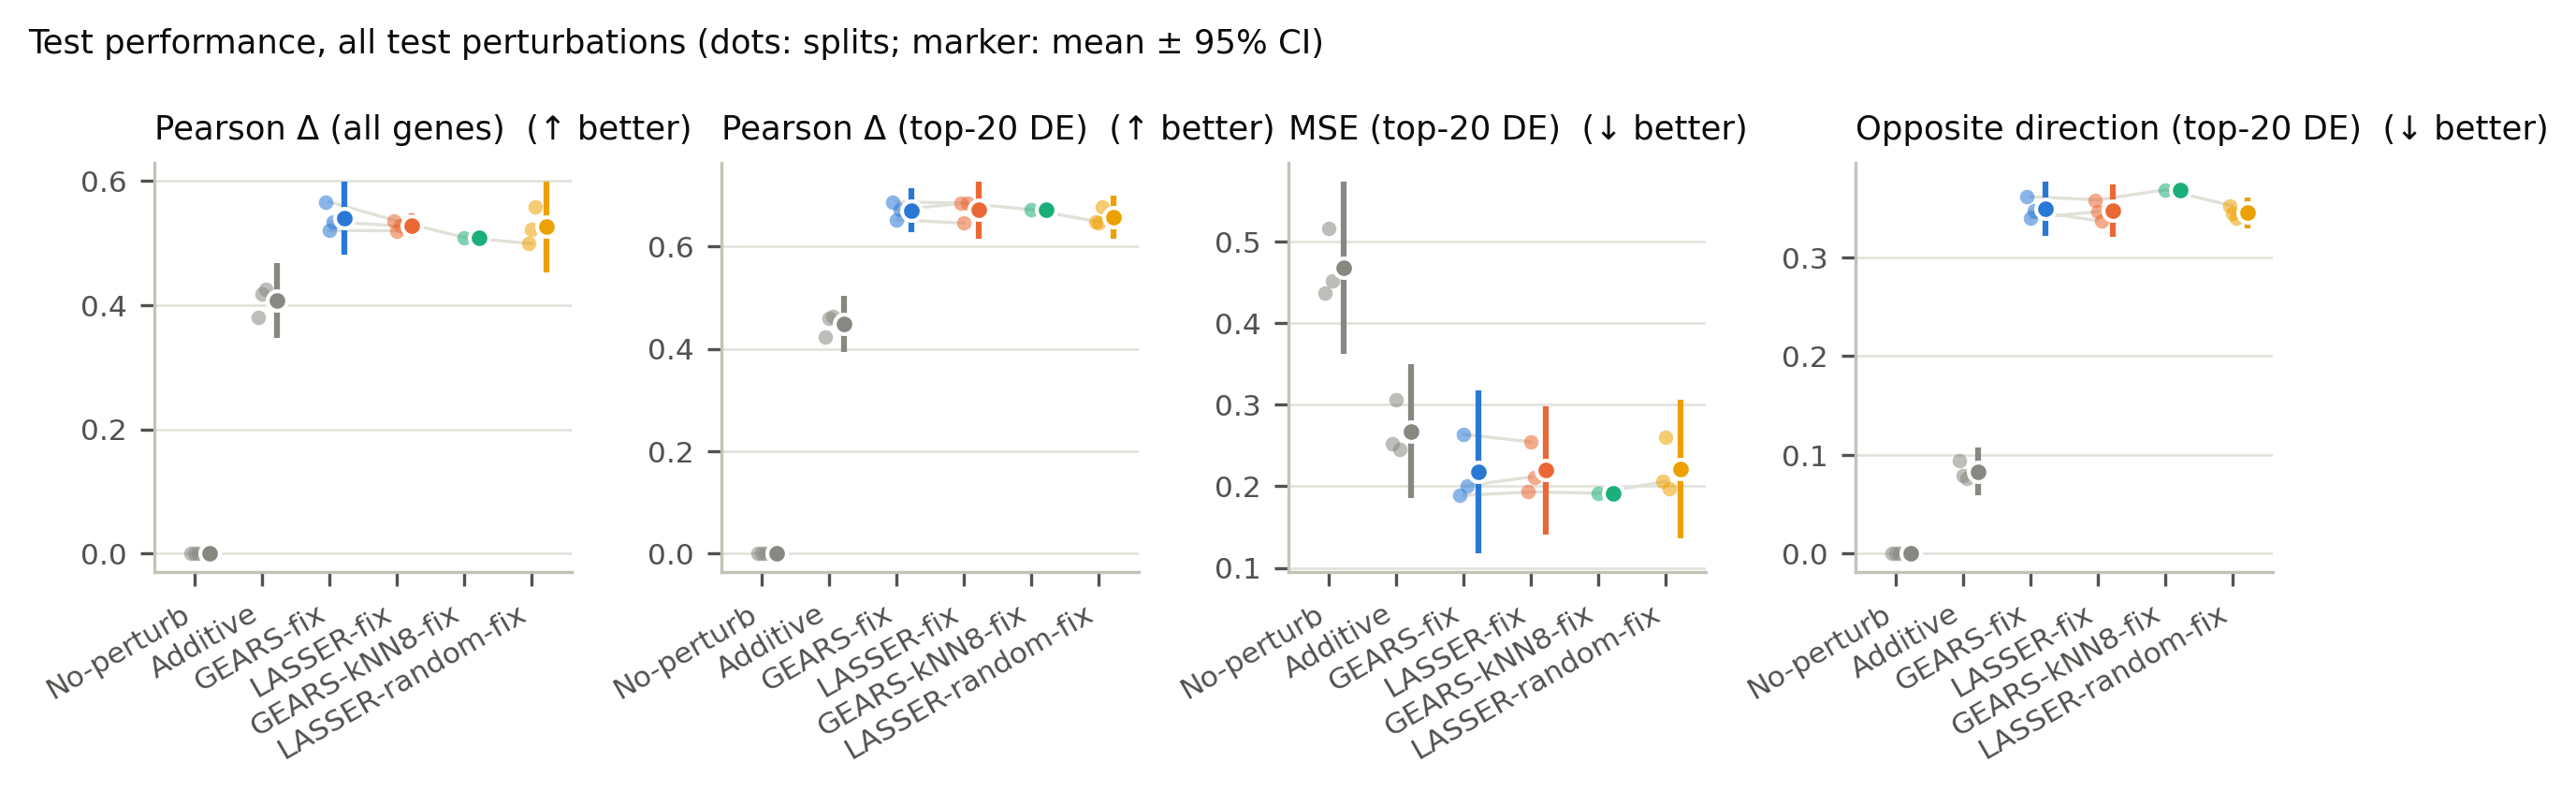

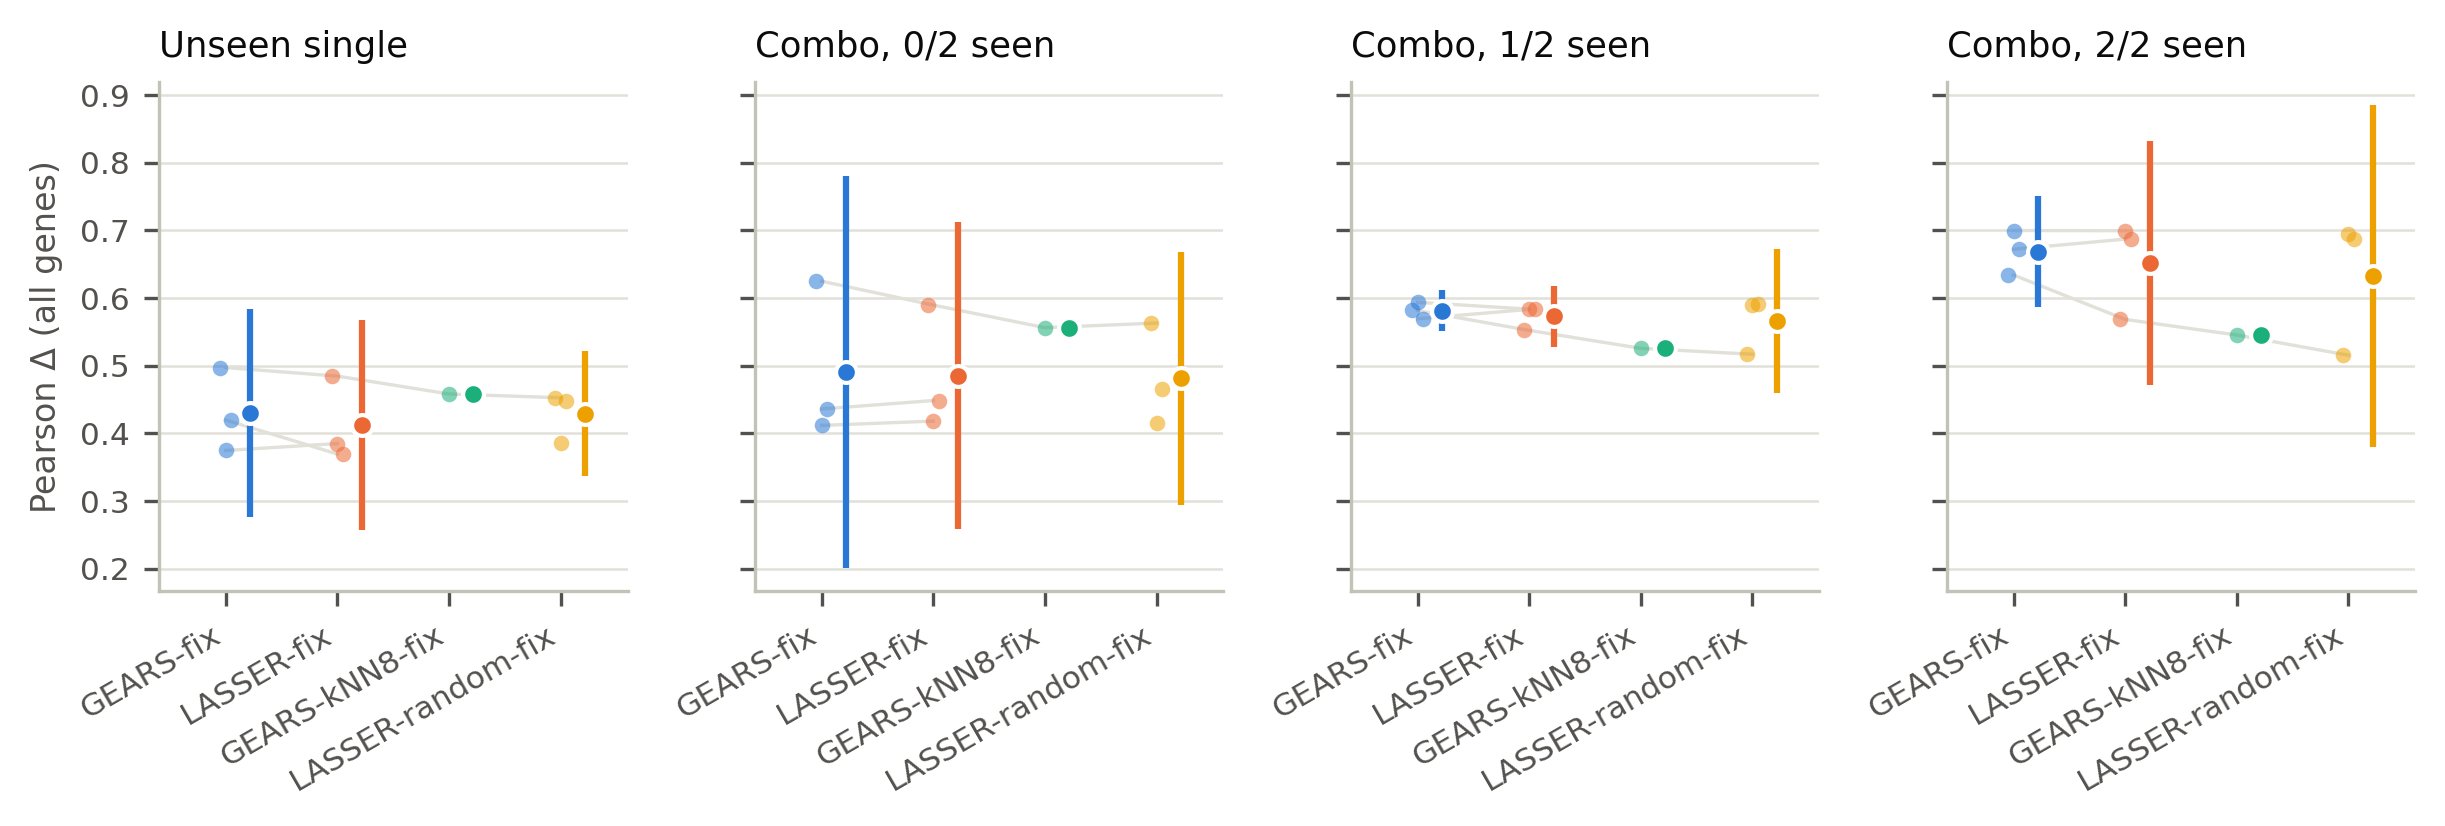

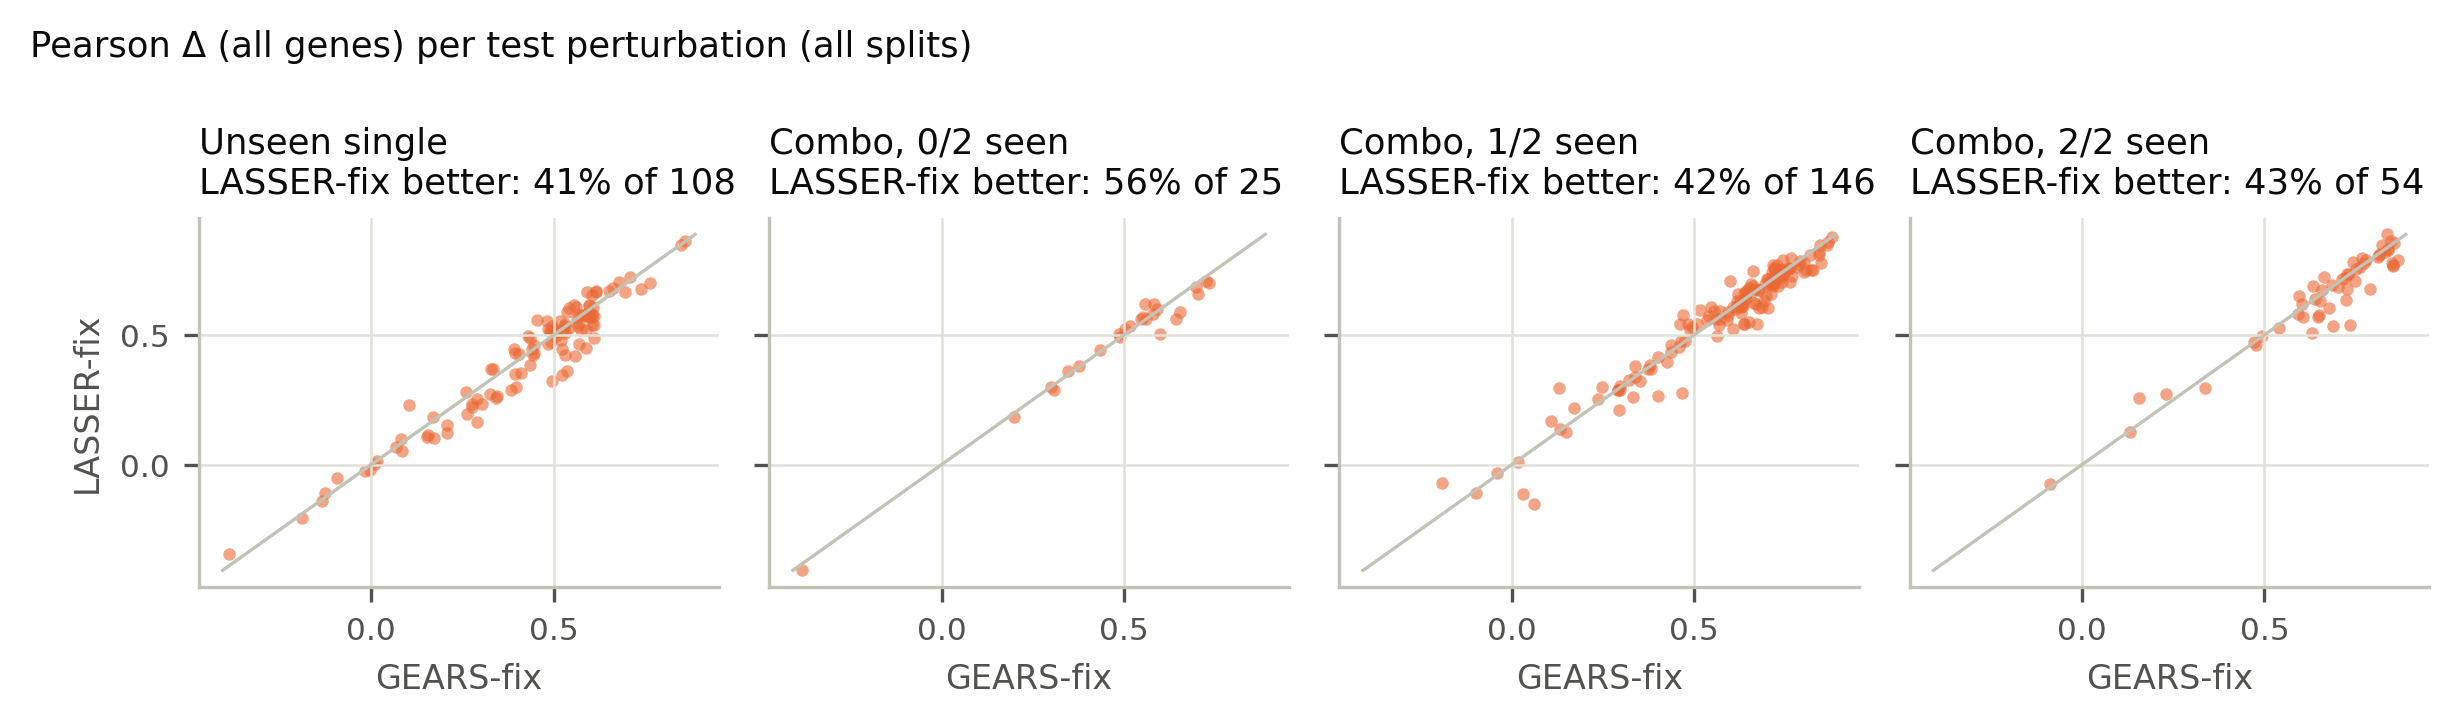

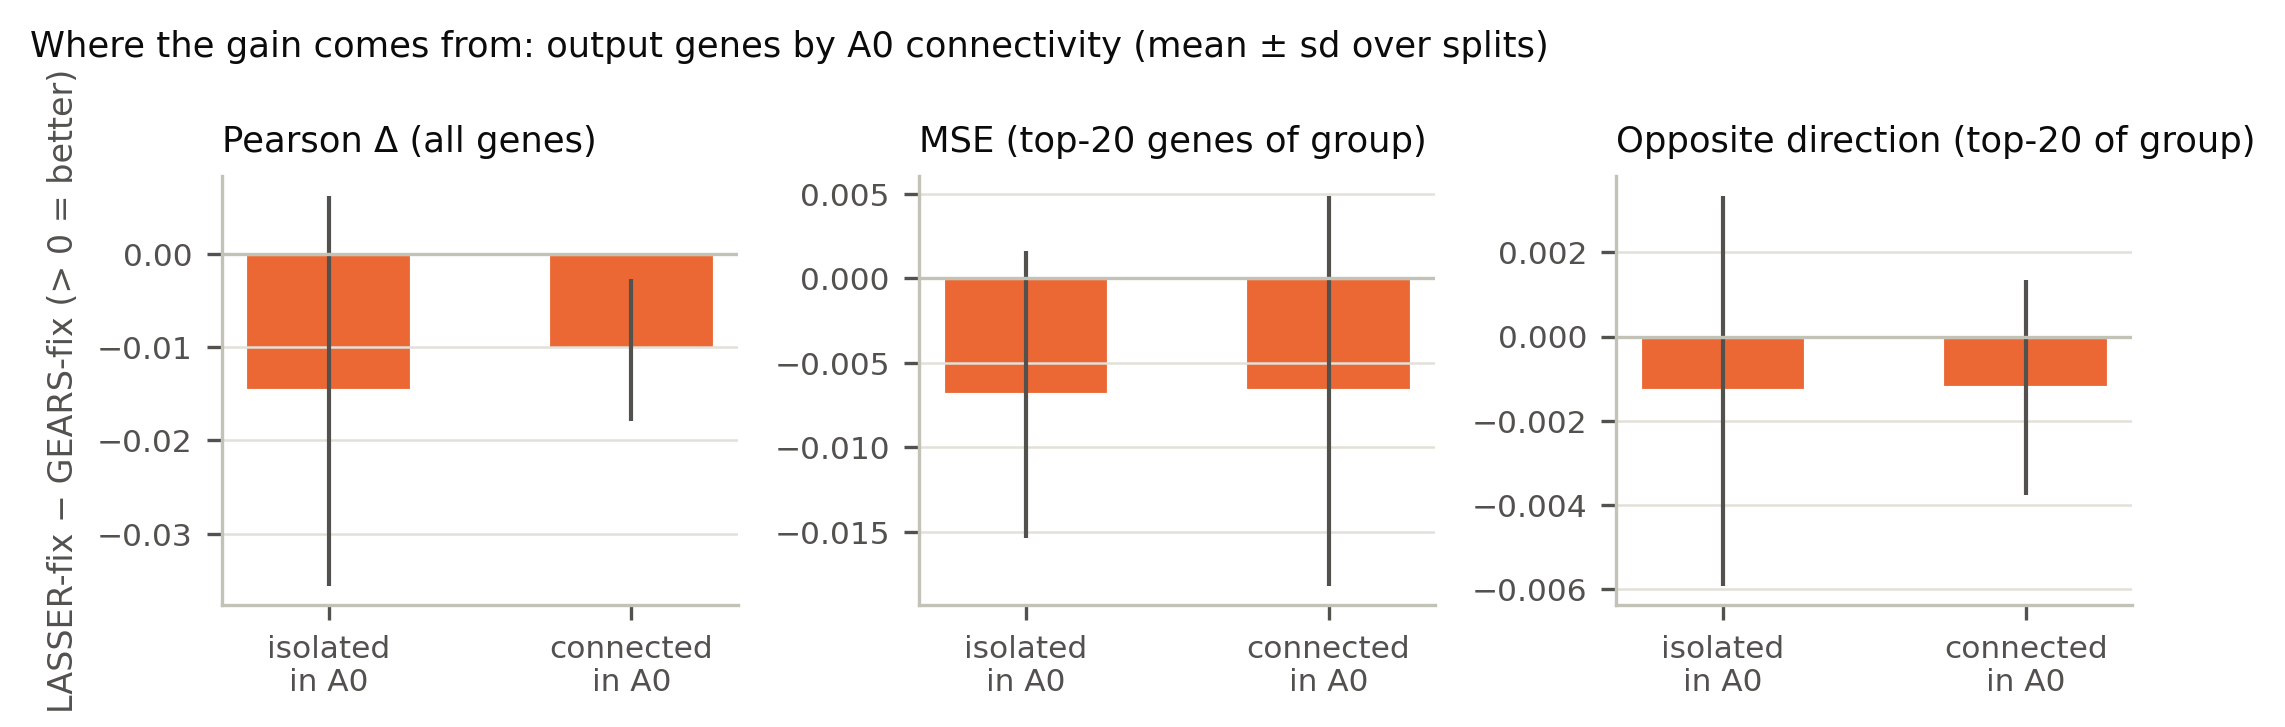

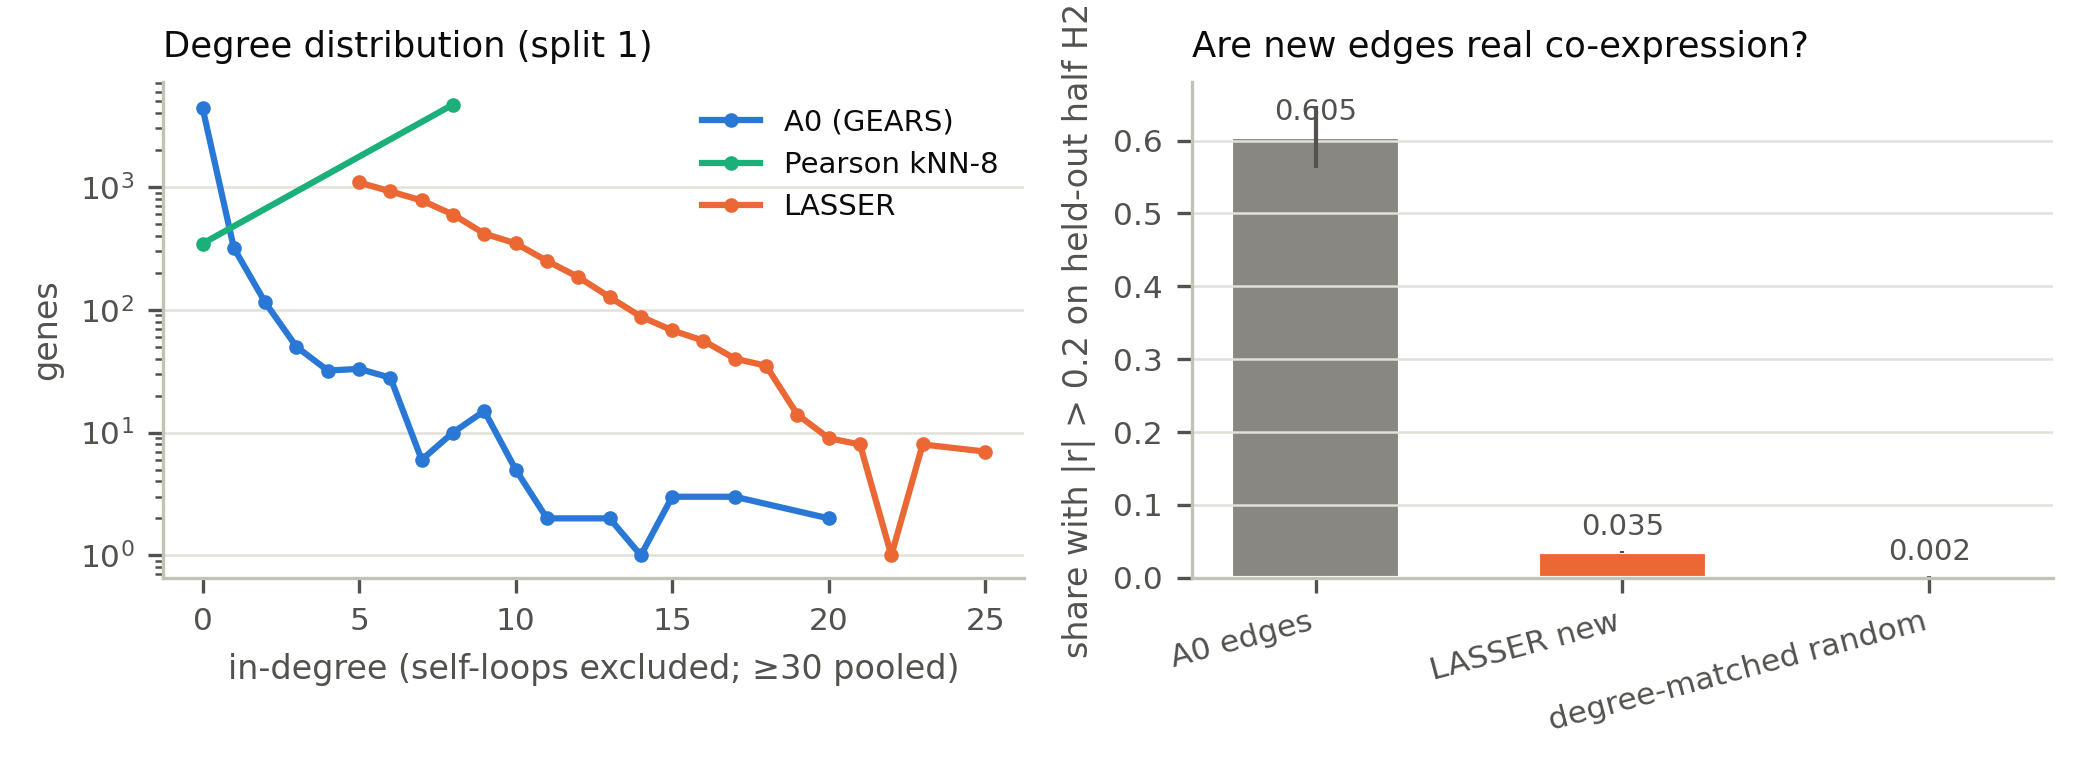

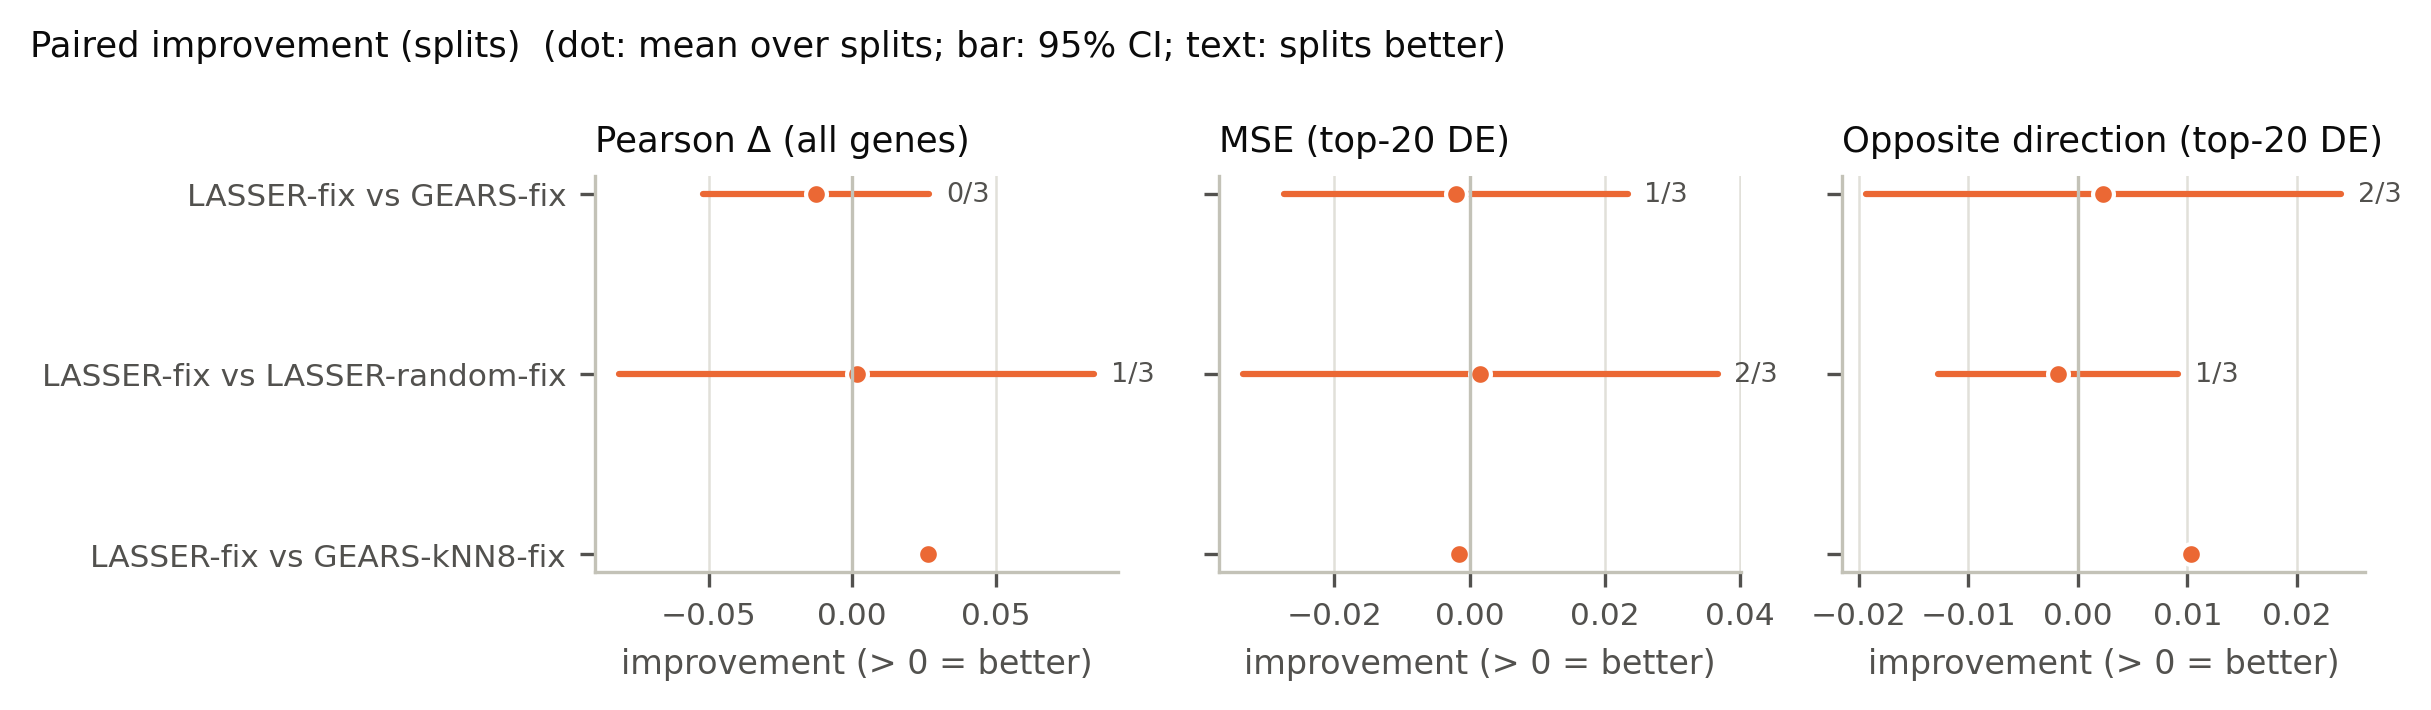

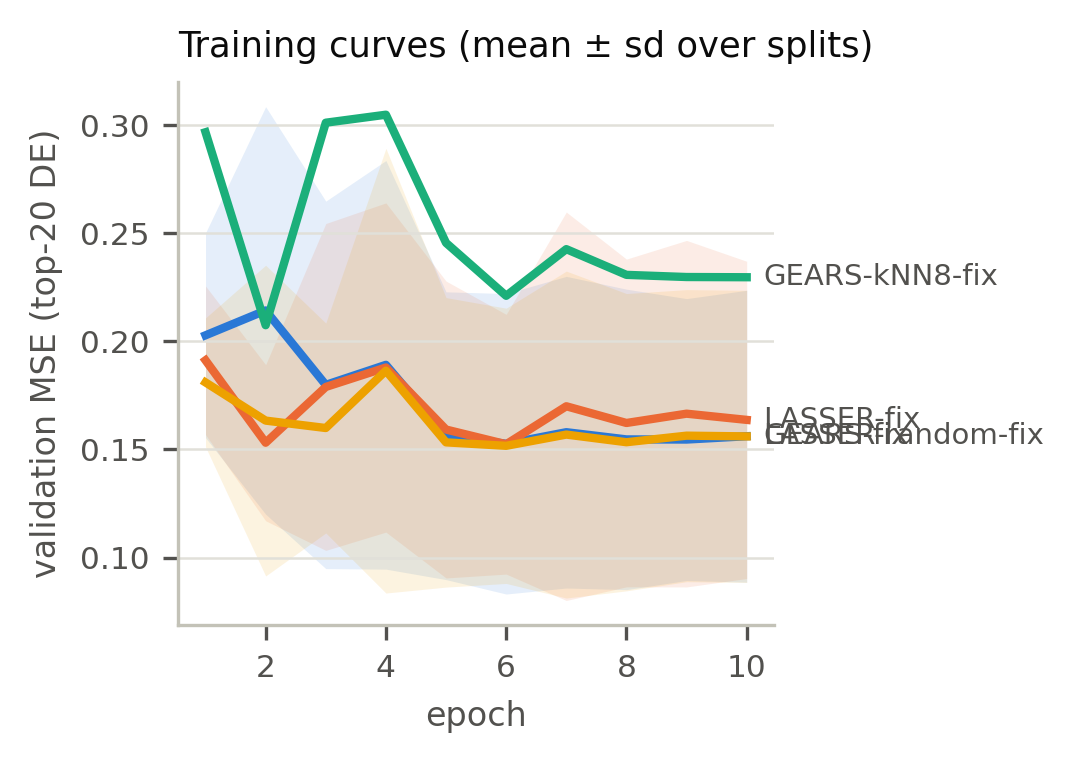

In [15]:
# 15. Figures (PDF + PNG).
paths = []
if ARMS:
    paths += F.fig_headline(long, REFS + ARMS, FIG_DIR)
    paths += F.fig_subgroups(long, ARMS, FIG_DIR)
if {"GEARS-fix", "LASSER-fix"} <= set(ARMS):
    paths += F.fig_per_perturbation(pp, FIG_DIR, ref="GEARS-fix", arm="LASSER-fix")
    paths += F.fig_gene_groups(t5, FIG_DIR, arm="LASSER-fix")
    paths += F.fig_graphs(gt, runs, FIG_DIR, a0_arm="GEARS-fix", knn_arm="GEARS-kNN8-fix",
                          lasser_arm="LASSER-fix", random_arm="LASSER-random-fix")
if len(t2):
    paths += F.fig_forest(t2[t2.unit == "split"], FIG_DIR, "fig_forest_fix", "Paired improvement (splits)")
paths += F.fig_training(A.training_curves(runs), ARMS, FIG_DIR)
from IPython.display import Image, display as _d
for p in paths:
    if p.endswith(".png"):
        _d(Image(p, width=900))

In [16]:
# 16. Export and zip (download /kaggle/working/lasser_fix_study_results.zip).
A.export_tables({"table1_headline": t1, "table1_subgroups": t1_sub, "table2_paired": t2,
                 "table3_paired_perturbations": t3, "table5_gene_groups": t5, "graph_stats": gt,
                 "consensus_edges": consensus}, RESULTS_DIR)
!cd {STUDY_DIR} && zip -qr /kaggle/working/lasser_fix_study_results.zip results figures runs/runs.csv runs/jobs.json runs/logs
print(sorted(os.listdir(RESULTS_DIR)))

['consensus_edges.csv', 'consensus_edges.tex', 'graph_stats.csv', 'graph_stats.tex', 'table1_headline.csv', 'table1_headline.tex', 'table1_subgroups.csv', 'table1_subgroups.tex', 'table2_paired.csv', 'table2_paired.tex', 'table3_paired_perturbations.csv', 'table3_paired_perturbations.tex', 'table5_gene_groups.csv', 'table5_gene_groups.tex']


## C. Reading the results

- **The claim** is `LASSER-fix > GEARS-fix` **and** `LASSER-fix > LASSER-random-fix` (and ideally
  `> GEARS-kNN8-fix`) on the paired tests, with an improvement larger than the run-to-run noise in cell 12.
- If `GEARS-fix` vs `GEARS` is large, the fix itself is a finding: published GEARS barely uses its co-expression
  graph.
- With 3 splits, p-values are weak by construction (paired *t*-test, n = 3). Report effect sizes with CIs,
  splits-better counts and the per-perturbation analysis, and add splits 4–5 (tier 6) in a later session before
  submission.